# MODEL: Custom CNN (Built from Scratch)
TASK : Crop Pest and Disease Detection - End-to-End Pipeline
Paste each CELL block into a separate cell in your Jupyter Notebook.
Run cells in order from top to bottom.

---


### Digital Image Processing Concepts Used in This Model

In digital image processing (DIP) for precision agriculture, crop pest and disease detection operates directly on discrete pixel arrays to identify localized and systemic plant pathologies. Crop disease symptoms—such as necrotic lesions, chlorotic rings, powdery fungal sporulation, and leaf miner serpentine tunnels—manifest as distinct spatial, chromatic, and textural variations against healthy foliage.

#### Why Crop Images Require Preprocessing
1. **Field Illumination Variations:** Uncontrolled outdoor lighting creates intense specular highlights, deep shadows, and variable color temperatures that alter raw pixel intensity values.
2. **Scale and Perspective Differences:** Unconstrained capture distances and camera angles alter the apparent size and geometric orientation of leaf symptoms.
3. **Complex Background Clutter:** Soil, weeds, dried organic matter, and neighboring foliage introduce high-frequency visual noise that must be handled robustly.
4. **Sensor Noise and Downsampling Artifacts:** Sensor acquisition noise and spatial quantization require systematic normalization.

#### Spatial and Intensity Transformations in Training
- **Geometric Transformations:** Random spatial reflections (flipping), rotations, zoom scaling, and spatial translations teach the model rotational and scale invariance, simulating varied drone and handheld camera viewpoints.
- **Intensity Transformations:** Contrast adjustment and brightness scaling simulate diurnal illumination shifts and camera exposure differences without altering underlying lesion morphology.

#### Convolutional Feature Extraction in Custom CNN
Unlike traditional DIP pipelines that rely on handcrafted spatial filters (e.g., fixed Sobel, Prewitt, or Laplacian operators) and manual feature descriptors (e.g., GLCM, LBP), a Convolutional Neural Network (CNN) learns **adaptive spatial convolution kernels** directly from training data.
- **Early layers** apply small $3\times 3$ kernels to extract low-level spatial primitives: edges, color gradients, and fine leaf margins.
- **Intermediate layers** synthesize these primitives into texture patterns and lesion borders.
- **Deep layers** aggregate localized patterns into high-level semantic representations of specific crop diseases.

#### End-to-End DIP & Classification Pipeline
$$\text{Input Image } (H \times W \times 3) \longrightarrow \text{Image Decoding \& Resizing } (128 \times 128) \longrightarrow \text{Data Augmentation } \longrightarrow \text{Pixel Rescaling } [0, 1] \longrightarrow \text{Convolutional Feature Extraction } \longrightarrow \text{Global Pooling } \longrightarrow \text{Dense Classification}$$

> **Important Case Study Note:** This model performs **whole-image classification** (predicting the overall disease category for the entire image) rather than explicit **semantic pixel segmentation** (which would delineate exact boundary contours for each diseased lesion).

### CELL 1 ── Install Dependencies


In [1]:
!pip install -q split-folders scikit-learn seaborn matplotlib tensorflow

### CELL 2 ── Imports


In [2]:
import os
import warnings
import splitfolders
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.22.0-rc0
GPU Available: []


### CELL 3 ── Verify & Load Local Dataset  (70 / 15 / 15)


In [3]:
# ==============================================================================
# DATASET PATH CONFIGURATION (Local Dataset in this folder)
# ==============================================================================
# The dataset is stored locally in this project directory.
# - 'Dataset_Split': contains pre-split train (70%), val (15%), and test (15%) sets
# - 'dataset': contains the raw unsplit 22 disease/pest class folders

def resolve_path(folder_name):
    """Resolve local dataset folder path in the project workspace."""
    candidates = [
        folder_name,
        os.path.join(os.getcwd(), folder_name),
        os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else ".", folder_name),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return folder_name

SPLIT_DIR = resolve_path("Dataset_Split")
RAW_DIR   = resolve_path("dataset")

if os.path.exists(SPLIT_DIR):
    print(f"[OK] Using local split dataset from: '{SPLIT_DIR}'")
elif os.path.exists(RAW_DIR):
    print(f"[NOTE] 'Dataset_Split' not found. Splitting local dataset from: '{RAW_DIR}' (70/15/15)...")
    splitfolders.ratio(RAW_DIR, output=SPLIT_DIR, seed=42, ratio=(0.70, 0.15, 0.15), group_prefix=None)
    print("[OK] Split complete.")
else:
    raise FileNotFoundError(
        f"Dataset not found in this folder! Looked for '{SPLIT_DIR}' and '{RAW_DIR}'. "
        "Please ensure the dataset folder is located in the project directory."
    )

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "val")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

print(f"  --> Train path : {TRAIN_DIR}")
print(f"  --> Val path   : {VAL_DIR}")
print(f"  --> Test path  : {TEST_DIR}")


[OK] Using local split dataset from: 'Dataset_Split'
  --> Train path : Dataset_Split\train
  --> Val path   : Dataset_Split\val
  --> Test path  : Dataset_Split\test


### DIP: Digital Image Representation, Decoding, and Spatial Resizing

#### Digital Color Image Representation
A digital color photograph is represented as a 3D numerical matrix of shape $(H \times W \times C)$, where:
- $H$ is the spatial height (number of pixel rows).
- $W$ is the spatial width (number of pixel columns).
- $C = 3$ represents the three additive primary color channels: **Red (R), Green (G), and Blue (B)**.
- Each pixel intensity is an 8-bit unsigned integer ($uint8$) with discrete levels spanning $[0, 255]$ ($2^8 = 256$ intensity levels).

#### Image Decoding
Stored JPEG images are compressed using Discrete Cosine Transform (DCT) quantization and Huffman entropy coding. During input pipeline execution, TensorFlow's decoding engine decompresses raw binary bitstreams into uncompressed 3D arrays of numerical pixel intensities.

#### Image Resizing and Spatial Downsampling
Deep neural networks process data in batches, requiring fixed, standardized tensor dimensions ($B \times H \times W \times C$).
- **Custom CNN Resolution:** This notebook standardizes all input images to **$128 \times 128$ pixels**.
- **Computational Trade-Off:** Resizing from high camera resolution (e.g., $400 \times 400$ or higher) to $128 \times 128$ drastically reduces computational complexity and GPU memory footprint ($128 \times 128 \times 3 = 49,152$ values vs. $400 \times 400 \times 3 = 480,000$ values—nearly a **$10\times$ reduction**).
- **Resolution Loss:** Aggressive spatial downsampling can attenuate high-frequency visual details, potentially blurring subtle early-stage disease symptoms such as micro-pustules or thin leaf miner tracks.
- **Aspect Ratio Distortion:** Direct bilinear downsampling to a square ($128 \times 128$) may cause geometric stretching if the original camera capture is non-square.

### CELL 4 ── Hyper-parameters & Data Loaders


In [4]:
BATCH_SIZE = 32
IMG_SIZE   = (128, 128)  # Smaller size for custom CNN — faster training
EPOCHS     = 2
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 17568 files belonging to 22 classes.
Found 3761 files belonging to 22 classes.
Found 3795 files belonging to 22 classes.
Classes (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']


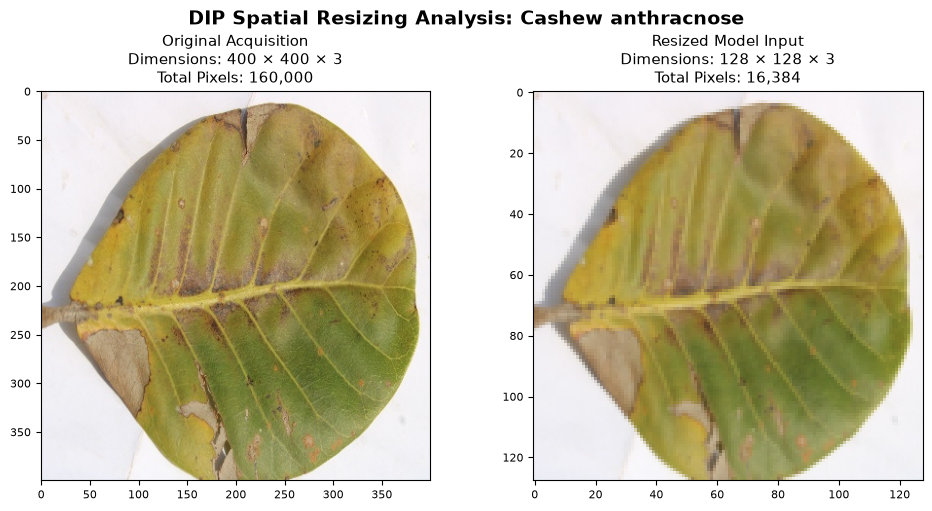

Spatial reduction ratio: 9.77x fewer pixels.


In [5]:
# DIP VISUALIZATION: Original Image vs. Resized Model Input (128x128)
import glob
from PIL import Image

# Retrieve an actual sample image from the training directory
sample_search = glob.glob(os.path.join(TRAIN_DIR, "*", "*.jpg"))
if sample_search:
    sample_file_path = sample_search[0]
    class_folder_name = os.path.basename(os.path.dirname(sample_file_path))
    
    # Load original image using PIL
    orig_img = Image.open(sample_file_path)
    orig_w, orig_h = orig_img.size
    
    # Perform standard bilinear downsampling to model input size (128x128)
    resized_img = orig_img.resize(IMG_SIZE, Image.BILINEAR)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"DIP Spatial Resizing Analysis: {class_folder_name}", fontsize=14, fontweight="bold")
    
    # Original image
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original Acquisition\nDimensions: {orig_h} × {orig_w} × 3\nTotal Pixels: {orig_h * orig_w:,}", fontsize=11)
    axes[0].axis("on")
    axes[0].tick_params(labelsize=8)
    
    # Resized image
    axes[1].imshow(resized_img)
    axes[1].set_title(f"Resized Model Input\nDimensions: {IMG_SIZE[1]} × {IMG_SIZE[0]} × 3\nTotal Pixels: {IMG_SIZE[0] * IMG_SIZE[1]:,}", fontsize=11)
    axes[1].axis("on")
    axes[1].tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()
    print(f"Spatial reduction ratio: {(orig_h * orig_w) / (IMG_SIZE[0] * IMG_SIZE[1]):.2f}x fewer pixels.")
else:
    print("No images found for resizing demonstration.")

### CELL 5 ── Explore: Sample Images


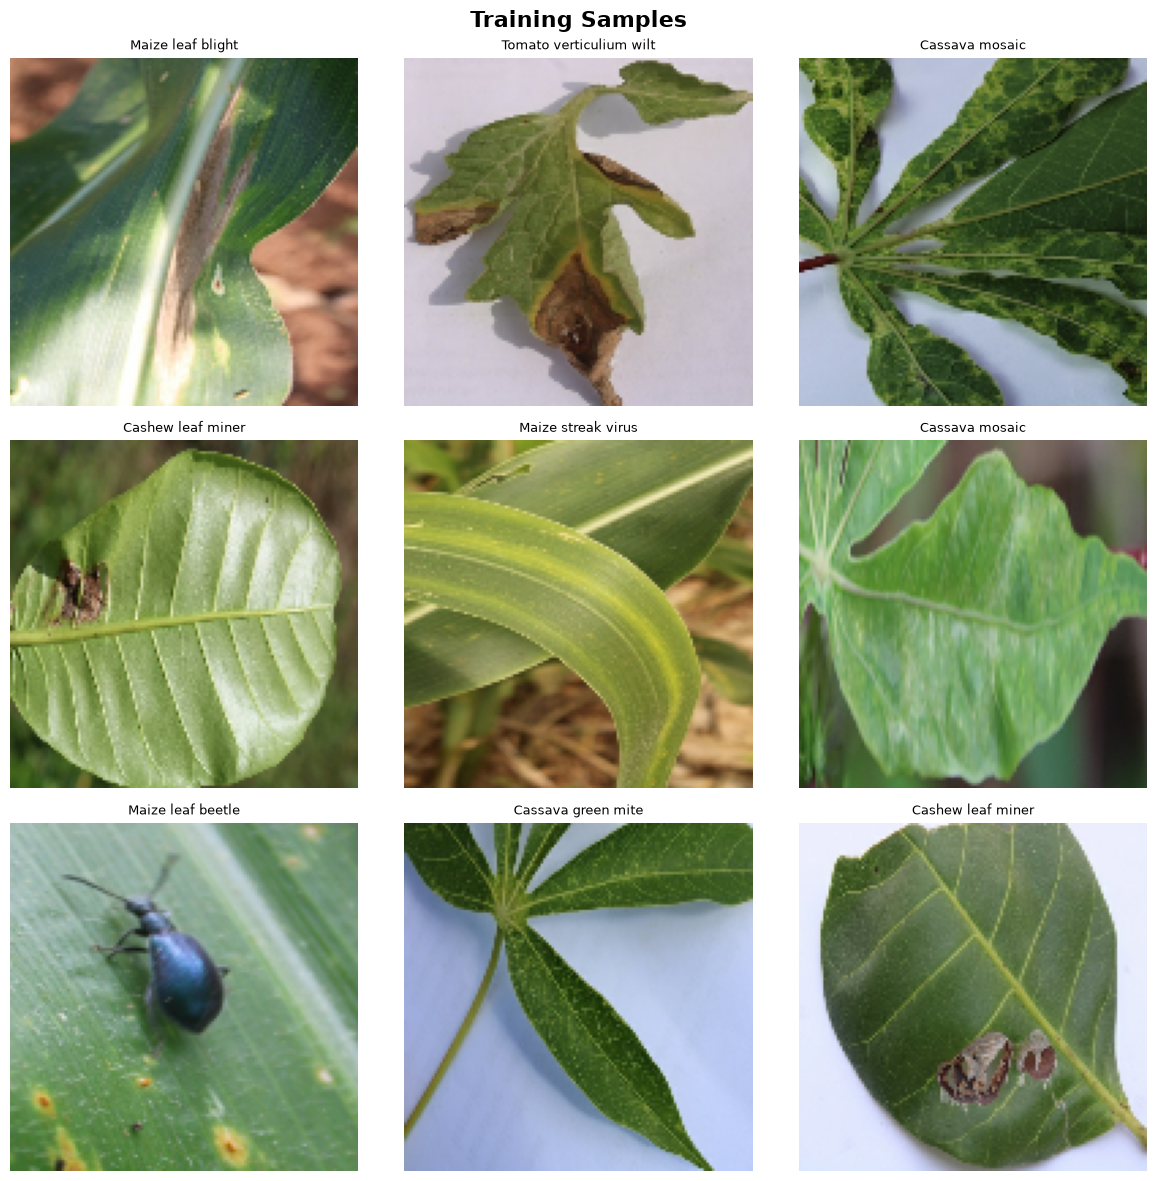

In [6]:
plt.figure(figsize=(12, 12))
plt.suptitle("Training Samples", fontsize=16, fontweight="bold")
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]], fontsize=9)
        plt.axis("off")
plt.tight_layout(); plt.show()

### DIP Demonstration: Digital Image Representation and Intensity Analysis

In digital image processing, color channels provide critical discriminative features for plant pathology. Diseased leaf tissue undergoes physiological breakdown causing **chlorosis** (loss of chlorophyll resulting in yellowing) and **necrosis** (cell death resulting in brown/black coloration).

Below, we perform an educational exploratory analysis on an actual crop image:
1. Decomposing the image into separate Red, Green, and Blue intensity channels.
2. Converting the RGB image to Grayscale using standard perceptual luminance weighting:
   $$Y = 0.299R + 0.587G + 0.114B$$
3. Computing pixel intensity histograms across RGB channels and the grayscale image to inspect pixel distribution across the $[0, 255]$ dynamic range.

> **Note on Pipeline Integrity:** This demonstration is purely exploratory. The model's training pipeline retains full 3-channel RGB images to preserve vital chromatic diagnostic cues.

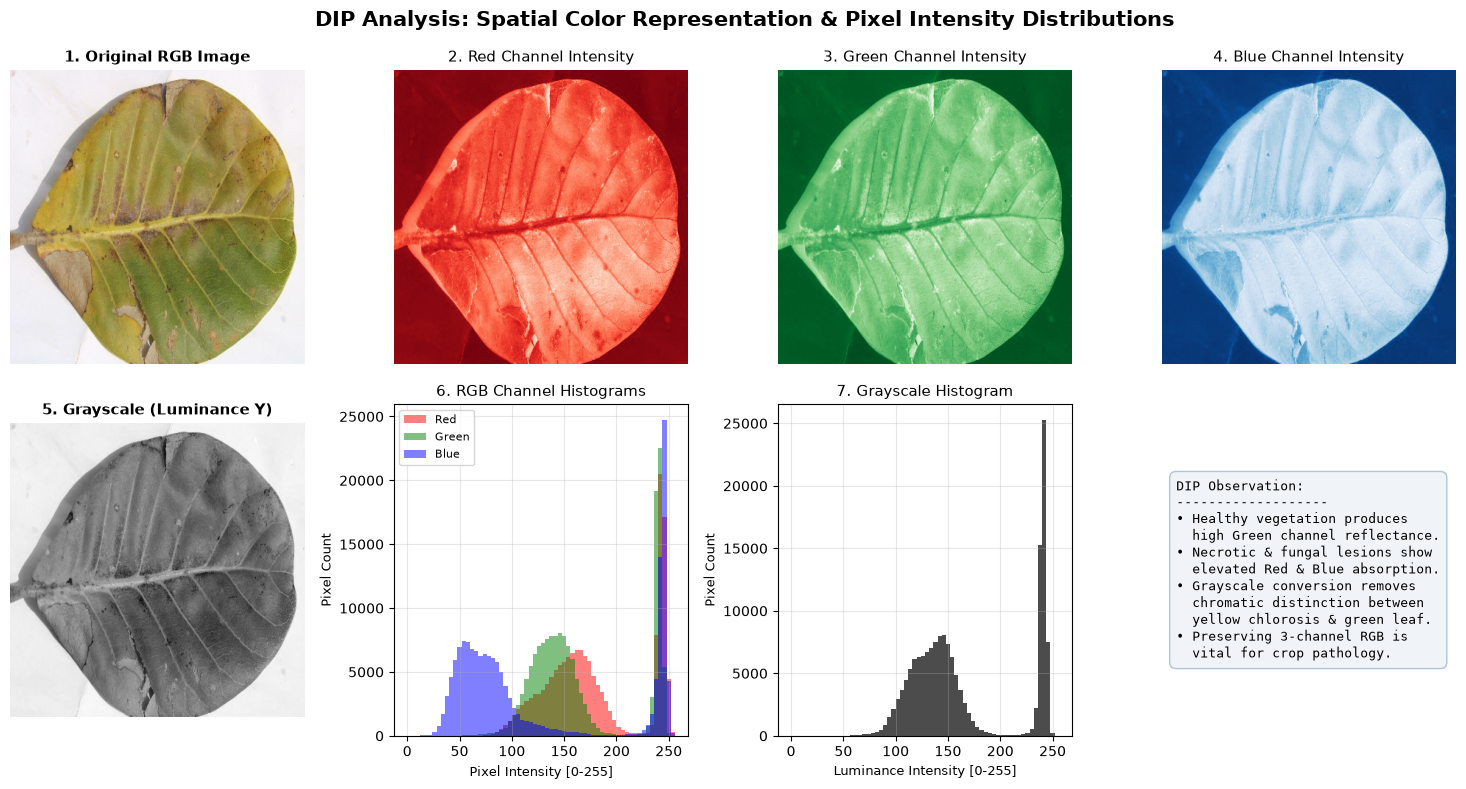

In [7]:
# DIP DEMONSTRATION: RGB Channel Decomposition, Grayscale Conversion & Intensity Histograms
if sample_search:
    raw_img = Image.open(sample_search[0]).convert("RGB")
    raw_np  = np.array(raw_img)
    
    # Grayscale conversion using ITU-R BT.601 perceptual luminance weights
    gray_np = (0.299 * raw_np[:, :, 0] + 0.587 * raw_np[:, :, 1] + 0.114 * raw_np[:, :, 2]).astype(np.uint8)
    
    fig = plt.figure(figsize=(15, 8))
    fig.suptitle("DIP Analysis: Spatial Color Representation & Pixel Intensity Distributions", fontsize=15, fontweight="bold")
    
    # 1. Original RGB Image
    ax1 = plt.subplot(2, 4, 1)
    ax1.imshow(raw_np)
    ax1.set_title("1. Original RGB Image", fontsize=11, fontweight="bold")
    ax1.axis("off")
    
    # 2. Red Channel
    ax2 = plt.subplot(2, 4, 2)
    ax2.imshow(raw_np[:, :, 0], cmap="Reds")
    ax2.set_title("2. Red Channel Intensity", fontsize=11)
    ax2.axis("off")
    
    # 3. Green Channel
    ax3 = plt.subplot(2, 4, 3)
    ax3.imshow(raw_np[:, :, 1], cmap="Greens")
    ax3.set_title("3. Green Channel Intensity", fontsize=11)
    ax3.axis("off")
    
    # 4. Blue Channel
    ax4 = plt.subplot(2, 4, 4)
    ax4.imshow(raw_np[:, :, 2], cmap="Blues")
    ax4.set_title("4. Blue Channel Intensity", fontsize=11)
    ax4.axis("off")
    
    # 5. Grayscale Conversion
    ax5 = plt.subplot(2, 4, 5)
    ax5.imshow(gray_np, cmap="gray")
    ax5.set_title("5. Grayscale (Luminance Y)", fontsize=11, fontweight="bold")
    ax5.axis("off")
    
    # 6. Combined RGB Intensity Histograms
    ax6 = plt.subplot(2, 4, 6)
    ax6.hist(raw_np[:, :, 0].ravel(), bins=64, range=(0, 256), color="red", alpha=0.5, label="Red")
    ax6.hist(raw_np[:, :, 1].ravel(), bins=64, range=(0, 256), color="green", alpha=0.5, label="Green")
    ax6.hist(raw_np[:, :, 2].ravel(), bins=64, range=(0, 256), color="blue", alpha=0.5, label="Blue")
    ax6.set_title("6. RGB Channel Histograms", fontsize=11)
    ax6.set_xlabel("Pixel Intensity [0-255]", fontsize=9)
    ax6.set_ylabel("Pixel Count", fontsize=9)
    ax6.legend(fontsize=8)
    ax6.grid(alpha=0.3)
    
    # 7. Grayscale Intensity Histogram
    ax7 = plt.subplot(2, 4, 7)
    ax7.hist(gray_np.ravel(), bins=64, range=(0, 256), color="black", alpha=0.7)
    ax7.set_title("7. Grayscale Histogram", fontsize=11)
    ax7.set_xlabel("Luminance Intensity [0-255]", fontsize=9)
    ax7.set_ylabel("Pixel Count", fontsize=9)
    ax7.grid(alpha=0.3)
    
    # 8. Analytical observation
    ax8 = plt.subplot(2, 4, 8)
    ax8.axis("off")
    analysis_text = (
        "DIP Observation:\n"
        "-------------------\n"
        "• Healthy vegetation produces\n"
        "  high Green channel reflectance.\n"
        "• Necrotic & fungal lesions show\n"
        "  elevated Red & Blue absorption.\n"
        "• Grayscale conversion removes\n"
        "  chromatic distinction between\n"
        "  yellow chlorosis & green leaf.\n"
        "• Preserving 3-channel RGB is\n"
        "  vital for crop pathology."
    )
    ax8.text(0.05, 0.5, analysis_text, fontsize=9.5, family="monospace", va="center",
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#f0f4f8", edgecolor="#b0c4de"))
    
    plt.tight_layout()
    plt.show()

### CELL 6 ── Class Distribution


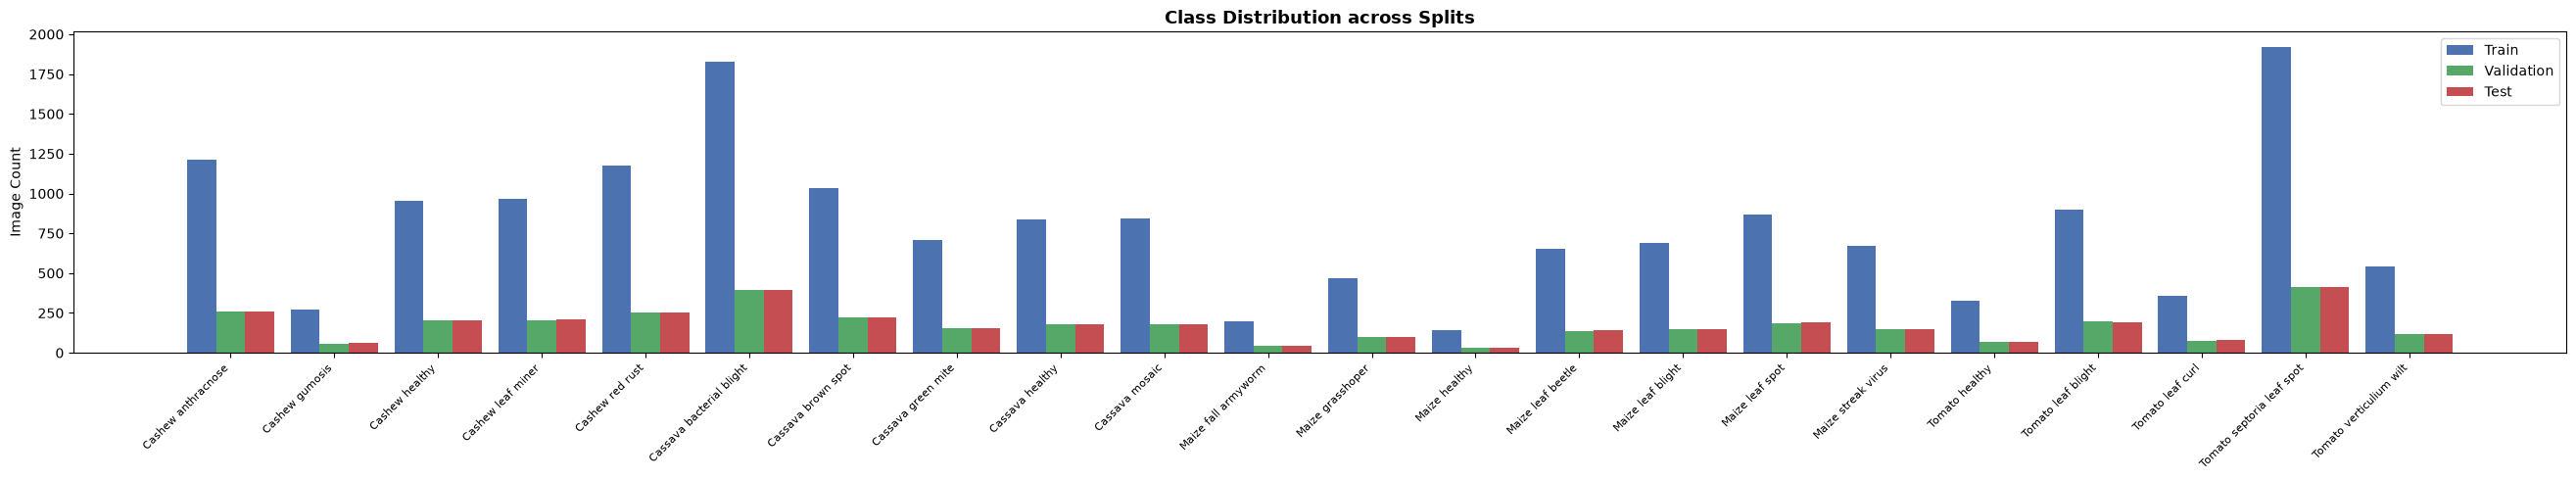

In [8]:
def count_classes(directory, class_names):
    return [len(os.listdir(os.path.join(directory, c))) for c in class_names]

train_counts = count_classes(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_classes(VAL_DIR,   CLASS_NAMES)
test_counts  = count_classes(TEST_DIR,  CLASS_NAMES)

x = np.arange(NUM_CLASSES)
w = 0.28
fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 1.2), 5))
ax.bar(x - w, train_counts, w, label="Train",      color="#4C72B0")
ax.bar(x,     val_counts,   w, label="Validation",  color="#55A868")
ax.bar(x + w, test_counts,  w, label="Test",        color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_title("Class Distribution across Splits", fontsize=13, fontweight="bold")
ax.set_ylabel("Image Count"); ax.legend()
plt.tight_layout(); plt.show()

### DIP: Geometric and Intensity Transformations

Data augmentation applies digital image processing transformations to synthetic training images, expanding effective dataset variance and enforcing invariance to camera orientation and field illumination.

#### 1. Geometric Transformations (Spatial Coordinate Remapping)
Geometric transformations alter the spatial coordinates $(x, y)$ of image pixels via 2D spatial mapping functions $I'(x', y') = I(T_x(x, y), T_y(x, y))$:
- **Spatial Reflection (Flipping):** `RandomFlip("horizontal_and_vertical")` reflects pixels across horizontal ($y' = H - y$) and vertical ($x' = W - x$) axes. Foliar diseases possess no natural gravitational orientation, making bilateral symmetry valid.
- **Rotation:** `RandomRotation(0.25)` applies 2D affine rotation. In Keras, a factor of **$0.25$ represents a fraction of $2\pi$**, meaning images are randomly rotated within $[-0.25 \times 360^\circ, +0.25 \times 360^\circ] = [-90^\circ, +90^\circ]$ (a full quarter turn), **not** 25 degrees.
- **Scaling (Zoom):** `RandomZoom(0.20)` scales coordinates by $\pm 20\%$, simulating variable camera working distances.
- **Translation:** `RandomTranslation(0.1, 0.1)` shifts the image spatially by $\pm 10\%$ along $x$ and $y$ axes, simulating off-center leaf framing.

#### 2. Intensity Transformations (Radiometric Point Operations)
Intensity transformations modify pixel intensity values directly without altering spatial pixel geometry:
- **Contrast Adjustment:** `RandomContrast(0.15)` dynamically stretches or compresses the image dynamic range around its mean intensity: $I'(x,y) = \bar{I} + c \cdot (I(x,y) - \bar{I})$, simulating variable ambient daylight and cloud cover.
- **Brightness Adjustment:** `RandomBrightness(0.10)` shifts intensity levels additively: $I'(x,y) = I(x,y) + \delta$, simulating overexposure or deep canopy shading.

### CELL 7 ── Data Augmentation


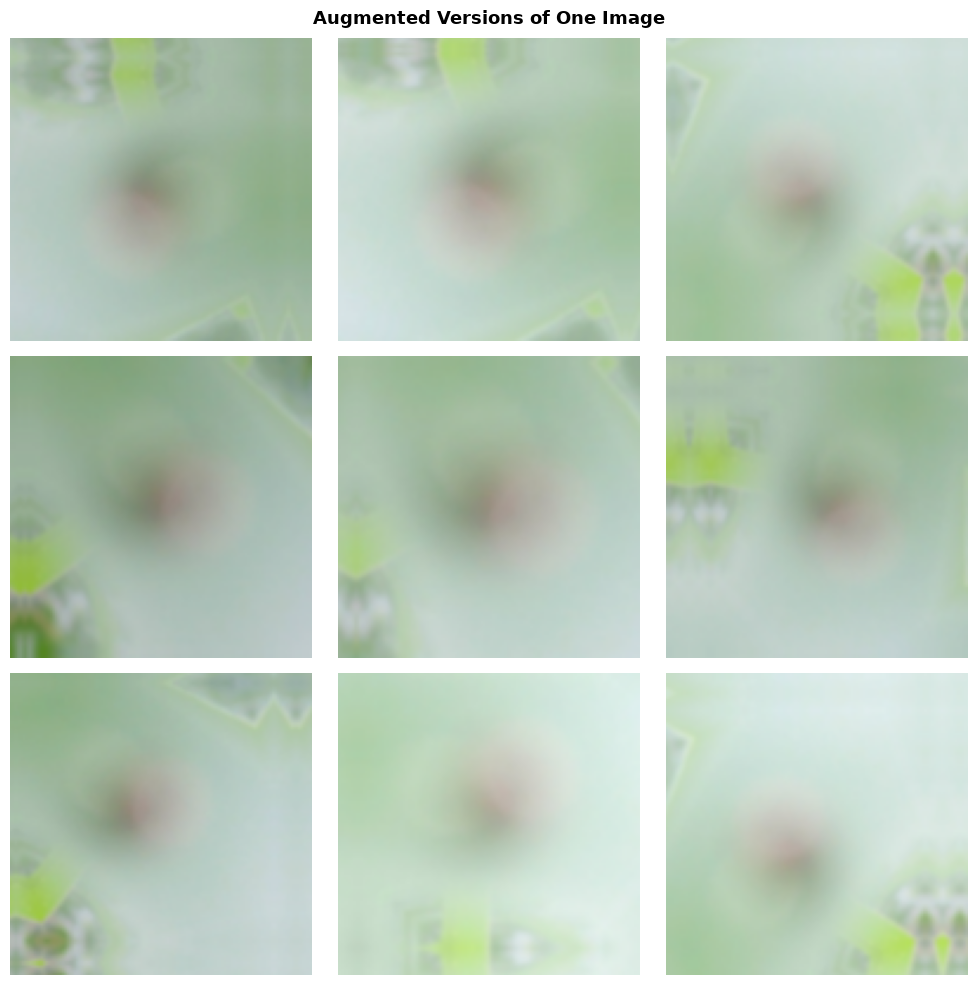

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.20),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

for images, _ in train_ds.take(1):
    sample = images[0]
aug_samples = [data_augmentation(tf.expand_dims(sample, 0))[0] for _ in range(9)]

plt.figure(figsize=(10, 10))
plt.suptitle("Augmented Versions of One Image", fontsize=13, fontweight="bold")
for i, img in enumerate(aug_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.show()

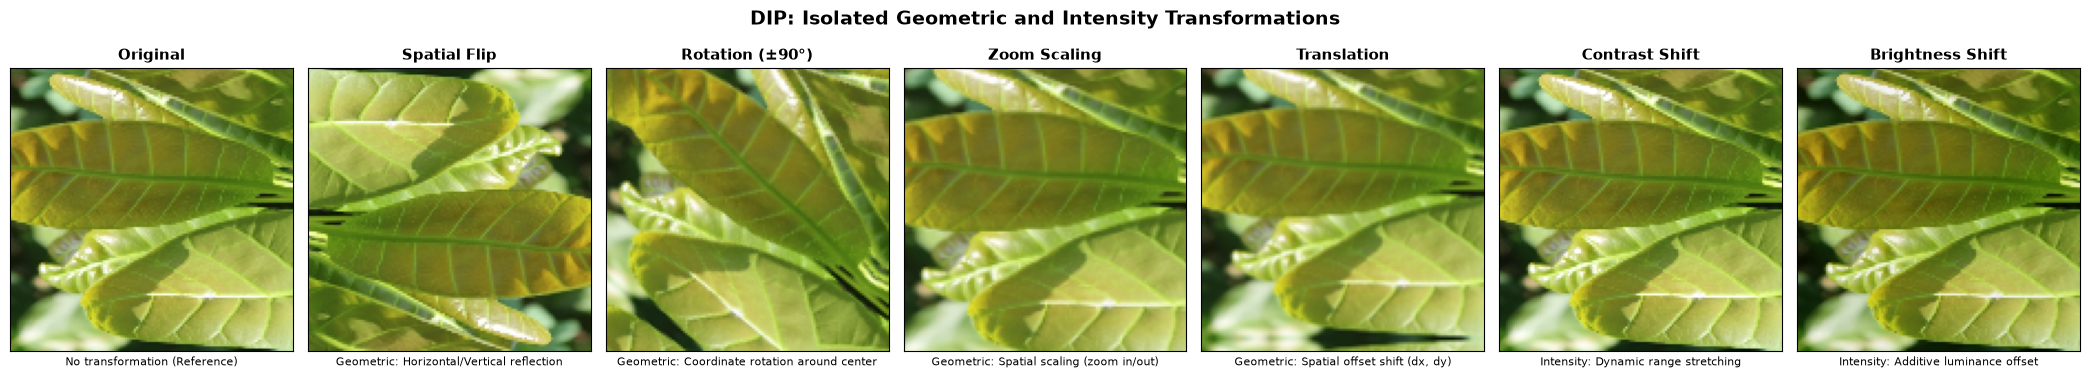

In [10]:
# DIP VISUALIZATION: Individual Geometric and Intensity Transformations Applied Separately
# We demonstrate each transformation supported in this notebook's augmentation pipeline individually
for images, _ in train_ds.take(1):
    base_sample = images[0]  # shape: (128, 128, 3), range: [0, 255]
    break

# Define individual transformation layers
t_flip  = layers.RandomFlip("horizontal_and_vertical", seed=42)
t_rot   = layers.RandomRotation(0.25, seed=42)            # +/- 90 degrees
t_zoom  = layers.RandomZoom(0.20, seed=42)                 # +/- 20% zoom
t_trans = layers.RandomTranslation(0.1, 0.1, seed=42)      # +/- 10% translation
t_cont  = layers.RandomContrast(0.15, seed=42)             # +/- 15% contrast
t_brit  = layers.RandomBrightness(0.10, value_range=(0, 255), seed=42) # +/- 10% brightness

sample_tensor = tf.expand_dims(base_sample, 0)

transforms_list = [
    ("Original", base_sample.numpy().astype("uint8"), "No transformation (Reference)"),
    ("Spatial Flip", t_flip(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Horizontal/Vertical reflection"),
    ("Rotation (±90°)", t_rot(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Coordinate rotation around center"),
    ("Zoom Scaling", t_zoom(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial scaling (zoom in/out)"),
    ("Translation", t_trans(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial offset shift (dx, dy)"),
    ("Contrast Shift", t_cont(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Dynamic range stretching"),
    ("Brightness Shift", t_brit(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Additive luminance offset"),
]

fig, axes = plt.subplots(1, 7, figsize=(21, 3.8))
fig.suptitle("DIP: Isolated Geometric and Intensity Transformations", fontsize=14, fontweight="bold")

for ax, (title, img_trans, desc) in zip(axes, transforms_list):
    ax.imshow(img_trans)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

### DIP: Convolutional Filtering and Hierarchical Feature Extraction

#### Mathematical Formulation of 2D Spatial Convolution
In discrete 2D digital image processing, spatial filtering correlates an input feature map $X$ with a 2D filter kernel $K$ of spatial dimensions $M \times N$:

$$Y(i, j) = (X * K)(i, j) = \sum_{m=-M/2}^{M/2} \sum_{n=-N/2}^{N/2} K(m, n) \cdot X(i + m, j + n)$$

Where:
- $X(i+m, j+n)$ is the pixel intensity or receptive field feature value at spatial offset $(m, n)$.
- $K(m, n)$ is the kernel weight matrix.
- $Y(i, j)$ is the filtered output response (activation feature map).
- In traditional DIP, $K$ is mathematically fixed (e.g., Sobel kernels for edge detection, Gaussian kernels for low-pass smoothing).
- In Convolutional Neural Networks, **all kernel weights $K(m, n)$ are learnable parameters** optimized via backpropagation to isolate crop disease indicators.

#### Hierarchical Feature Representation in Custom CNN
1. **Low-Level Layers (Block 1 - 32 filters):** Extract high-frequency spatial gradients, crisp leaf edges, color boundaries, and vein structures.
2. **Intermediate Layers (Blocks 2 & 3 - 64 & 128 filters):** Synthesize low-level gradients into textural primitives: circular fungal spots, chlorotic halos, and boundary contours.
3. **High-Level Layers (Blocks 4 & 5 - 256 & 512 filters):** Capture broad semantic representations: severe leaf blight spread, mosaic disfigurations, and distinctive pest damage.
4. **Global Average Pooling:** Converts spatial feature tensors $(B, H', W', C')$ into compact 1D vector representations $(B, C')$ by computing the spatial mean of each feature map:
   $$GAP_c = \frac{1}{H' \times W'} \sum_{i=1}^{H'} \sum_{j=1}^{W'} Y_c(i, j)$$
   This dramatically reduces parameter count compared to fully connected flattening and enforces translation invariance.

---

### DIP: Pixel Intensity Preprocessing

| Model | Preprocessing Operation | Input Scale Expected |
|---|---|---|
| **Custom CNN** | Linear Rescaling: $X' = \frac{X}{255.0}$ | Maps raw $[0, 255]$ uint8 to $[0.0, 1.0]$ float32 |

#### Critical Implementation Note: Augmentation and Normalization Ordering
In this updated pipeline:
- `data_augmentation` is applied **first** on raw $[0, 255]$ pixel values.
- This ensures `RandomBrightness(0.10, value_range=(0, 255))` and `RandomContrast` operate on their native $[0, 255]$ dynamic range without scale mismatch.
- `layers.Rescaling(1.0 / 255)` is applied immediately **after** augmentation, mapping the augmented tensors into $[0.0, 1.0]$ float32 before they enter the convolutional layers.
- Inputs are never rescaled twice.

### CELL 8 ── Build Custom CNN Architecture (from scratch)


In [11]:
# A deep 5-block CNN with Batch Normalization, increasing filters, and Dropout.
# DIP Pipeline: Raw Pixels [0, 255] -> Data Augmentation -> Rescaling [0, 1] -> Conv Blocks
def build_custom_cnn(num_classes, img_size):
    inputs = tf.keras.Input(shape=img_size + (3,), name="input")

    # Step 1: Apply spatial & intensity augmentations on raw [0, 255] pixel range
    x = data_augmentation(inputs)

    # Step 2: Normalize pixel intensities from [0, 255] to [0.0, 1.0] for stable gradient descent
    x = layers.Rescaling(1.0 / 255.0, name="pixel_rescaling")(x)

    # Block 1 — 32 filters (Receptive field: low-level edges & color transitions)
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(1e-4), name="block1_conv")(x)
    x = layers.BatchNormalization(name="block1_bn")(x)
    x = layers.MaxPooling2D((2, 2), name="block1_pool")(x)
    x = layers.Dropout(0.20)(x)

    # Block 2 — 64 filters (Receptive field: texture primitives & fine lesions)
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(1e-4), name="block2_conv")(x)
    x = layers.BatchNormalization(name="block2_bn")(x)
    x = layers.MaxPooling2D((2, 2), name="block2_pool")(x)
    x = layers.Dropout(0.25)(x)

    # Block 3 — 128 filters (Receptive field: spot boundaries & leaf structures)
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(1e-4), name="block3_conv")(x)
    x = layers.BatchNormalization(name="block3_bn")(x)
    x = layers.MaxPooling2D((2, 2), name="block3_pool")(x)
    x = layers.Dropout(0.30)(x)

    # Block 4 — 256 filters (Receptive field: composite disease patterns)
    x = layers.Conv2D(256, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(1e-4), name="block4_conv")(x)
    x = layers.BatchNormalization(name="block4_bn")(x)
    x = layers.MaxPooling2D((2, 2), name="block4_pool")(x)
    x = layers.Dropout(0.35)(x)

    # Block 5 — 512 filters (Receptive field: high-level semantic pathology)
    x = layers.Conv2D(512, (3, 3), padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(1e-4), name="block5_conv")(x)
    x = layers.BatchNormalization(name="block5_bn")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.40)(x)

    # Classification Head
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=regularizers.l2(1e-4), name="dense_features")(x)
    x = layers.BatchNormalization(name="dense_bn")(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model = tf.keras.Model(inputs, outputs, name="Custom_CNN_CropDisease")
    return model

model = build_custom_cnn(NUM_CLASSES, IMG_SIZE)
model.summary()

Model: "Custom_CNN_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_rescaling (Rescaling)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 16, 16, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv (Conv2D)            │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_bn (BatchNormalization)  │ (None, 8, 8, 512)      │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_bn (BatchNormalization)   │ (None, 256)            │         1,02

 Total params: 1,710,550 (6.53 MB)

 Trainable params: 1,708,054 (6.52 MB)

 Non-trainable params: 2,496 (9.75 KB)

### DIP Demonstration: Classical Spatial Filtering and Edge Detection

To contextualize how CNN convolution differs from classical digital image processing, we examine two fundamental handcrafted spatial filtering operations applied to a real crop disease image:

1. **Gaussian Smoothing (Low-Pass Filter):**
   $$G(x, y) = \frac{1}{2\pi \sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}}$$
   Attenuates high-frequency sensor noise and camera grain. However, excessive smoothing blurs delicate disease lesion margins.
2. **Sobel Gradient Operator (High-Pass Spatial Filtering):**
   Approximates discrete spatial derivatives across horizontal ($G_x$) and vertical ($G_y$) directions:
   $$G_x = \begin{bmatrix} -1 & 0 & +1 \\ -2 & 0 & +2 \\ -1 & 0 & +1 \end{bmatrix} * I, \quad G_y = \begin{bmatrix} +1 & +2 & +1 \\ 0 & 0 & 0 \\ -1 & -2 & -1 \end{bmatrix} * I$$
   The total gradient magnitude $|\nabla I| = \sqrt{G_x^2 + G_y^2}$ highlights high-contrast boundaries: leaf margins, structural veins, and disease lesion perimeters.

> **Key DIP Insight:** While classical Sobel and Gaussian filters rely on **fixed, hand-engineered mathematical coefficients**, a CNN optimizes its kernel matrices **adaptively from training data**, discovering complex oriented filters specialized for crop pathology.

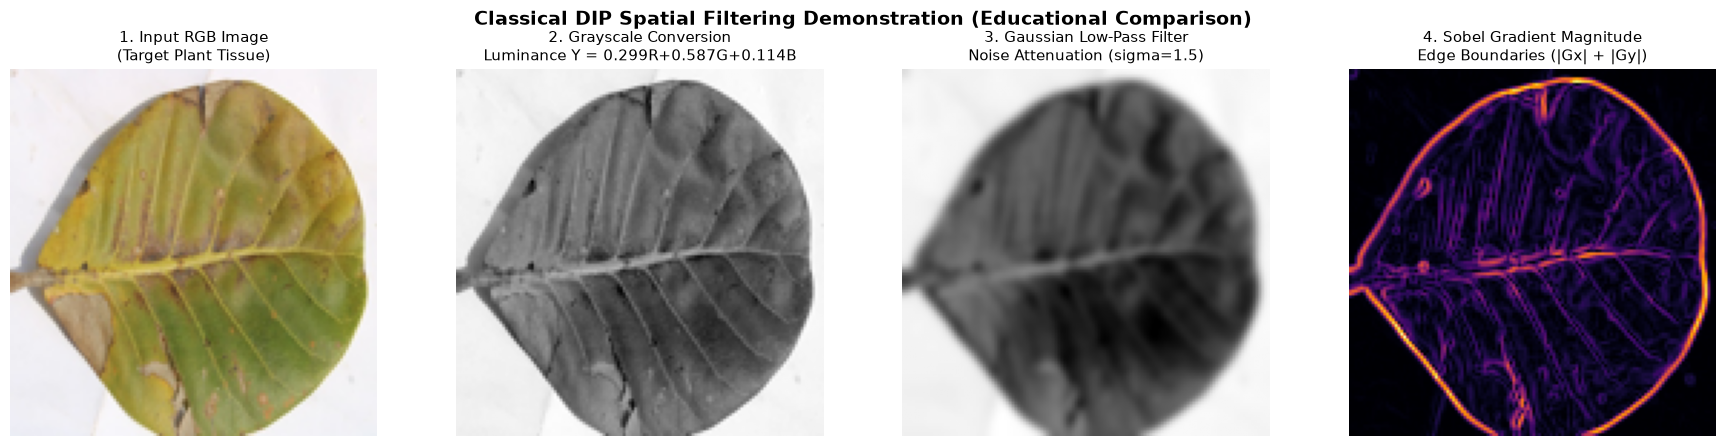

In [12]:
# DIP DEMONSTRATION: Gaussian Smoothing and Sobel Gradient Edge Detection
from scipy.ndimage import gaussian_filter, sobel

if sample_search:
    demo_pil = Image.open(sample_search[0]).convert("RGB").resize(IMG_SIZE)
    demo_np  = np.array(demo_pil)
    demo_gray = (0.299 * demo_np[:, :, 0] + 0.587 * demo_np[:, :, 1] + 0.114 * demo_np[:, :, 2]).astype(np.float32)
    
    # 1. Classical Gaussian Smoothing (sigma = 1.5)
    gauss_blurred = gaussian_filter(demo_gray, sigma=1.5)
    
    # 2. Classical Sobel Edge Filtering (horizontal and vertical spatial derivatives)
    grad_x = sobel(demo_gray, axis=1)
    grad_y = sobel(demo_gray, axis=0)
    sobel_magnitude = np.hypot(grad_x, grad_y)
    sobel_magnitude = (sobel_magnitude / (sobel_magnitude.max() + 1e-8) * 255).astype(np.uint8)
    
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    fig.suptitle("Classical DIP Spatial Filtering Demonstration (Educational Comparison)", fontsize=14, fontweight="bold")
    
    axes[0].imshow(demo_np)
    axes[0].set_title("1. Input RGB Image\n(Target Plant Tissue)", fontsize=11)
    axes[0].axis("off")
    
    axes[1].imshow(demo_gray, cmap="gray")
    axes[1].set_title("2. Grayscale Conversion\nLuminance Y = 0.299R+0.587G+0.114B", fontsize=11)
    axes[1].axis("off")
    
    axes[2].imshow(gauss_blurred, cmap="gray")
    axes[2].set_title("3. Gaussian Low-Pass Filter\nNoise Attenuation (sigma=1.5)", fontsize=11)
    axes[2].axis("off")
    
    axes[3].imshow(sobel_magnitude, cmap="inferno")
    axes[3].set_title("4. Sobel Gradient Magnitude\nEdge Boundaries (|Gx| + |Gy|)", fontsize=11)
    axes[3].axis("off")
    
    plt.tight_layout()
    plt.show()

### Digital Image Processing vs. Machine Learning in Model Training

It is essential in academic image processing to clearly distinguish the role of **Digital Image Processing (DIP)** from **Machine Learning (ML)**:

- **Image Processing Operations:** Resizing, geometric spatial remapping (flips, rotations, zooms), pixel intensity normalization ($[0, 255] \to [0, 1]$), 2D spatial convolution filtering, and pooling downsampling.
- **Machine Learning Operations:** Sparse categorical cross-entropy loss computation, error backpropagation via chain rule, Adam optimizer parameter updates, learning rate decay schedules (`ReduceLROnPlateau`), and regularization (dropout, early stopping).

DIP transforms raw sensor pixel arrays into structured spatial feature representations; Machine Learning optimizes network weights so those spatial representations yield high-accuracy disease classification.

### CELL 9 ── Compile & Train


In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb_early = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                   restore_best_weights=True, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                       patience=3, min_lr=1e-7, verbose=1)
cb_ckpt  = callbacks.ModelCheckpoint("best_custom_cnn.keras", save_best_only=True,
                                      monitor="val_accuracy", verbose=1)

history = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Training complete.")

Epoch 1/2


549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - accuracy: 0.2176 - loss: 2.9638
Epoch 1: val_accuracy improved from None to 0.17389, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 452s 761ms/step - accuracy: 0.2176 - loss: 2.9638 - val_accuracy: 0.1739 - val_loss: 3.3124 - learning_rate: 0.0010
Epoch 2/2
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - accuracy: 0.3383 - loss: 2.2663
Epoch 2: val_accuracy improved from 0.17389 to 0.44164, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 461s 839ms/step - accuracy: 0.3383 - loss: 2.2663 - val_accuracy: 0.4416 - val_loss: 1.9181 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.
Training complete.


### CELL 10 ── Training Curves


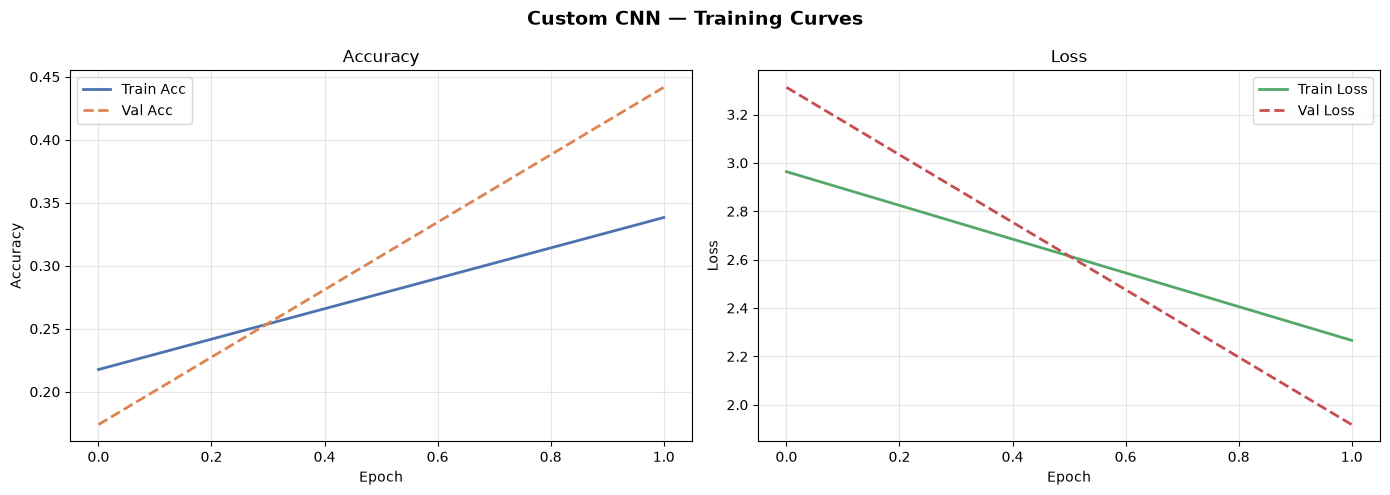

In [14]:
acc      = history.history["accuracy"]
val_acc  = history.history["val_accuracy"]
loss     = history.history["loss"]
val_loss = history.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Custom CNN — Training Curves", fontsize=14, fontweight="bold")

axes[0].plot(acc,     label="Train Acc",  linewidth=2, color="#4C72B0")
axes[0].plot(val_acc, label="Val Acc",    linewidth=2, color="#DD8452", linestyle="--")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(loss,     label="Train Loss", linewidth=2, color="#55A868")
axes[1].plot(val_loss, label="Val Loss",   linewidth=2, color="#C44E52", linestyle="--")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### CELL 11 ── Evaluate on Test Set


In [15]:
model.load_weights("best_custom_cnn.keras")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy : {test_acc  * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 23s 192ms/step - accuracy: 0.4435 - loss: 1.8882

Test Accuracy : 44.35%
Test Loss     : 1.8882


### DIP: Visualizing Learned Convolutional Feature Maps

To verify that the convolutional layers are functioning as spatial feature extractors, we pass a test image through the trained network and extract activation feature maps from the **first convolutional layer (`block1_conv`)**.

Each feature map represents the spatial response of a single learned $3 \times 3$ convolution filter across the image:
- Certain filters respond strongly to leaf boundary edges (high spatial frequencies).
- Others respond to smooth green foliage regions (low spatial frequencies).
- Others trigger on dark necrotic disease lesions or discolored chlorotic patches.

In [16]:
# DIP VISUALIZATION: Learned Convolutional Activation Feature Maps
if os.path.exists("best_custom_cnn.keras"):
    try:
        # Create an intermediate feature extraction model targeting Block 1 Conv
        feature_extractor = tf.keras.Model(
            inputs=model.get_layer("input").input,
            outputs=model.get_layer("block1_conv").output
        )
        
        # Grab a batch of test images
        for test_imgs, test_lbls in test_ds.take(1):
            sample_test_img = test_imgs[0:1] # shape (1, 128, 128, 3)
            true_label_idx  = test_lbls[0].numpy()
            break
            
        feature_maps = feature_extractor.predict(sample_test_img, verbose=0)
        # feature_maps shape: (1, 128, 128, 32)
        
        fig, axes = plt.subplots(2, 5, figsize=(15, 6))
        fig.suptitle(f"DIP Activation Maps: First Conv Layer Responses — {CLASS_NAMES[true_label_idx]}", fontsize=14, fontweight="bold")
        
        # Display original input image in first panel
        axes[0, 0].imshow(sample_test_img[0].numpy().astype("uint8"))
        axes[0, 0].set_title("Input Image", fontsize=10, fontweight="bold")
        axes[0, 0].axis("off")
        
        # Display 9 representative feature maps
        for idx in range(1, 10):
            r, c = divmod(idx, 5)
            fmap = feature_maps[0, :, :, idx - 1]
            axes[r, c].imshow(fmap, cmap="viridis")
            axes[r, c].set_title(f"Filter #{idx} Activation", fontsize=10)
            axes[r, c].axis("off")
            
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Feature map extraction skipped: {e}")
else:
    print("Feature map visualization requires 'best_custom_cnn.keras'. Train model to visualize.")

Feature map extraction skipped: `inputs` argument cannot be empty. Received:
inputs=[]
outputs=<KerasTensor shape=(None, 128, 128, 32), dtype=float32, sparse=False, ragged=False, name=keras_tensor_14>


### CELL 12 ── Confusion Matrix & Classification Report



Classification Report:
                           precision    recall  f1-score   support

       Cashew anthracnose     0.6549    0.2846    0.3968       260
           Cashew gumosis     0.7692    0.6667    0.7143        60
           Cashew healthy     0.5385    0.4417    0.4853       206
        Cashew leaf miner     0.5127    0.3894    0.4426       208
          Cashew red rust     0.7414    0.7708    0.7558       253
 Cassava bacterial blight     0.3794    0.4402    0.4075       393
       Cassava brown spot     0.3965    0.4036    0.4000       223
       Cassava green mite     0.2994    0.6732    0.4145       153
          Cassava healthy     0.3804    0.7778    0.5109       180
           Cassava mosaic     0.5625    0.0989    0.1682       182
      Maize fall armyworm     0.0000    0.0000    0.0000        44
         Maize grasshoper     0.2320    0.5686    0.3295       102
            Maize healthy     0.0000    0.0000    0.0000        32
        Maize leaf beetle     0.3324 

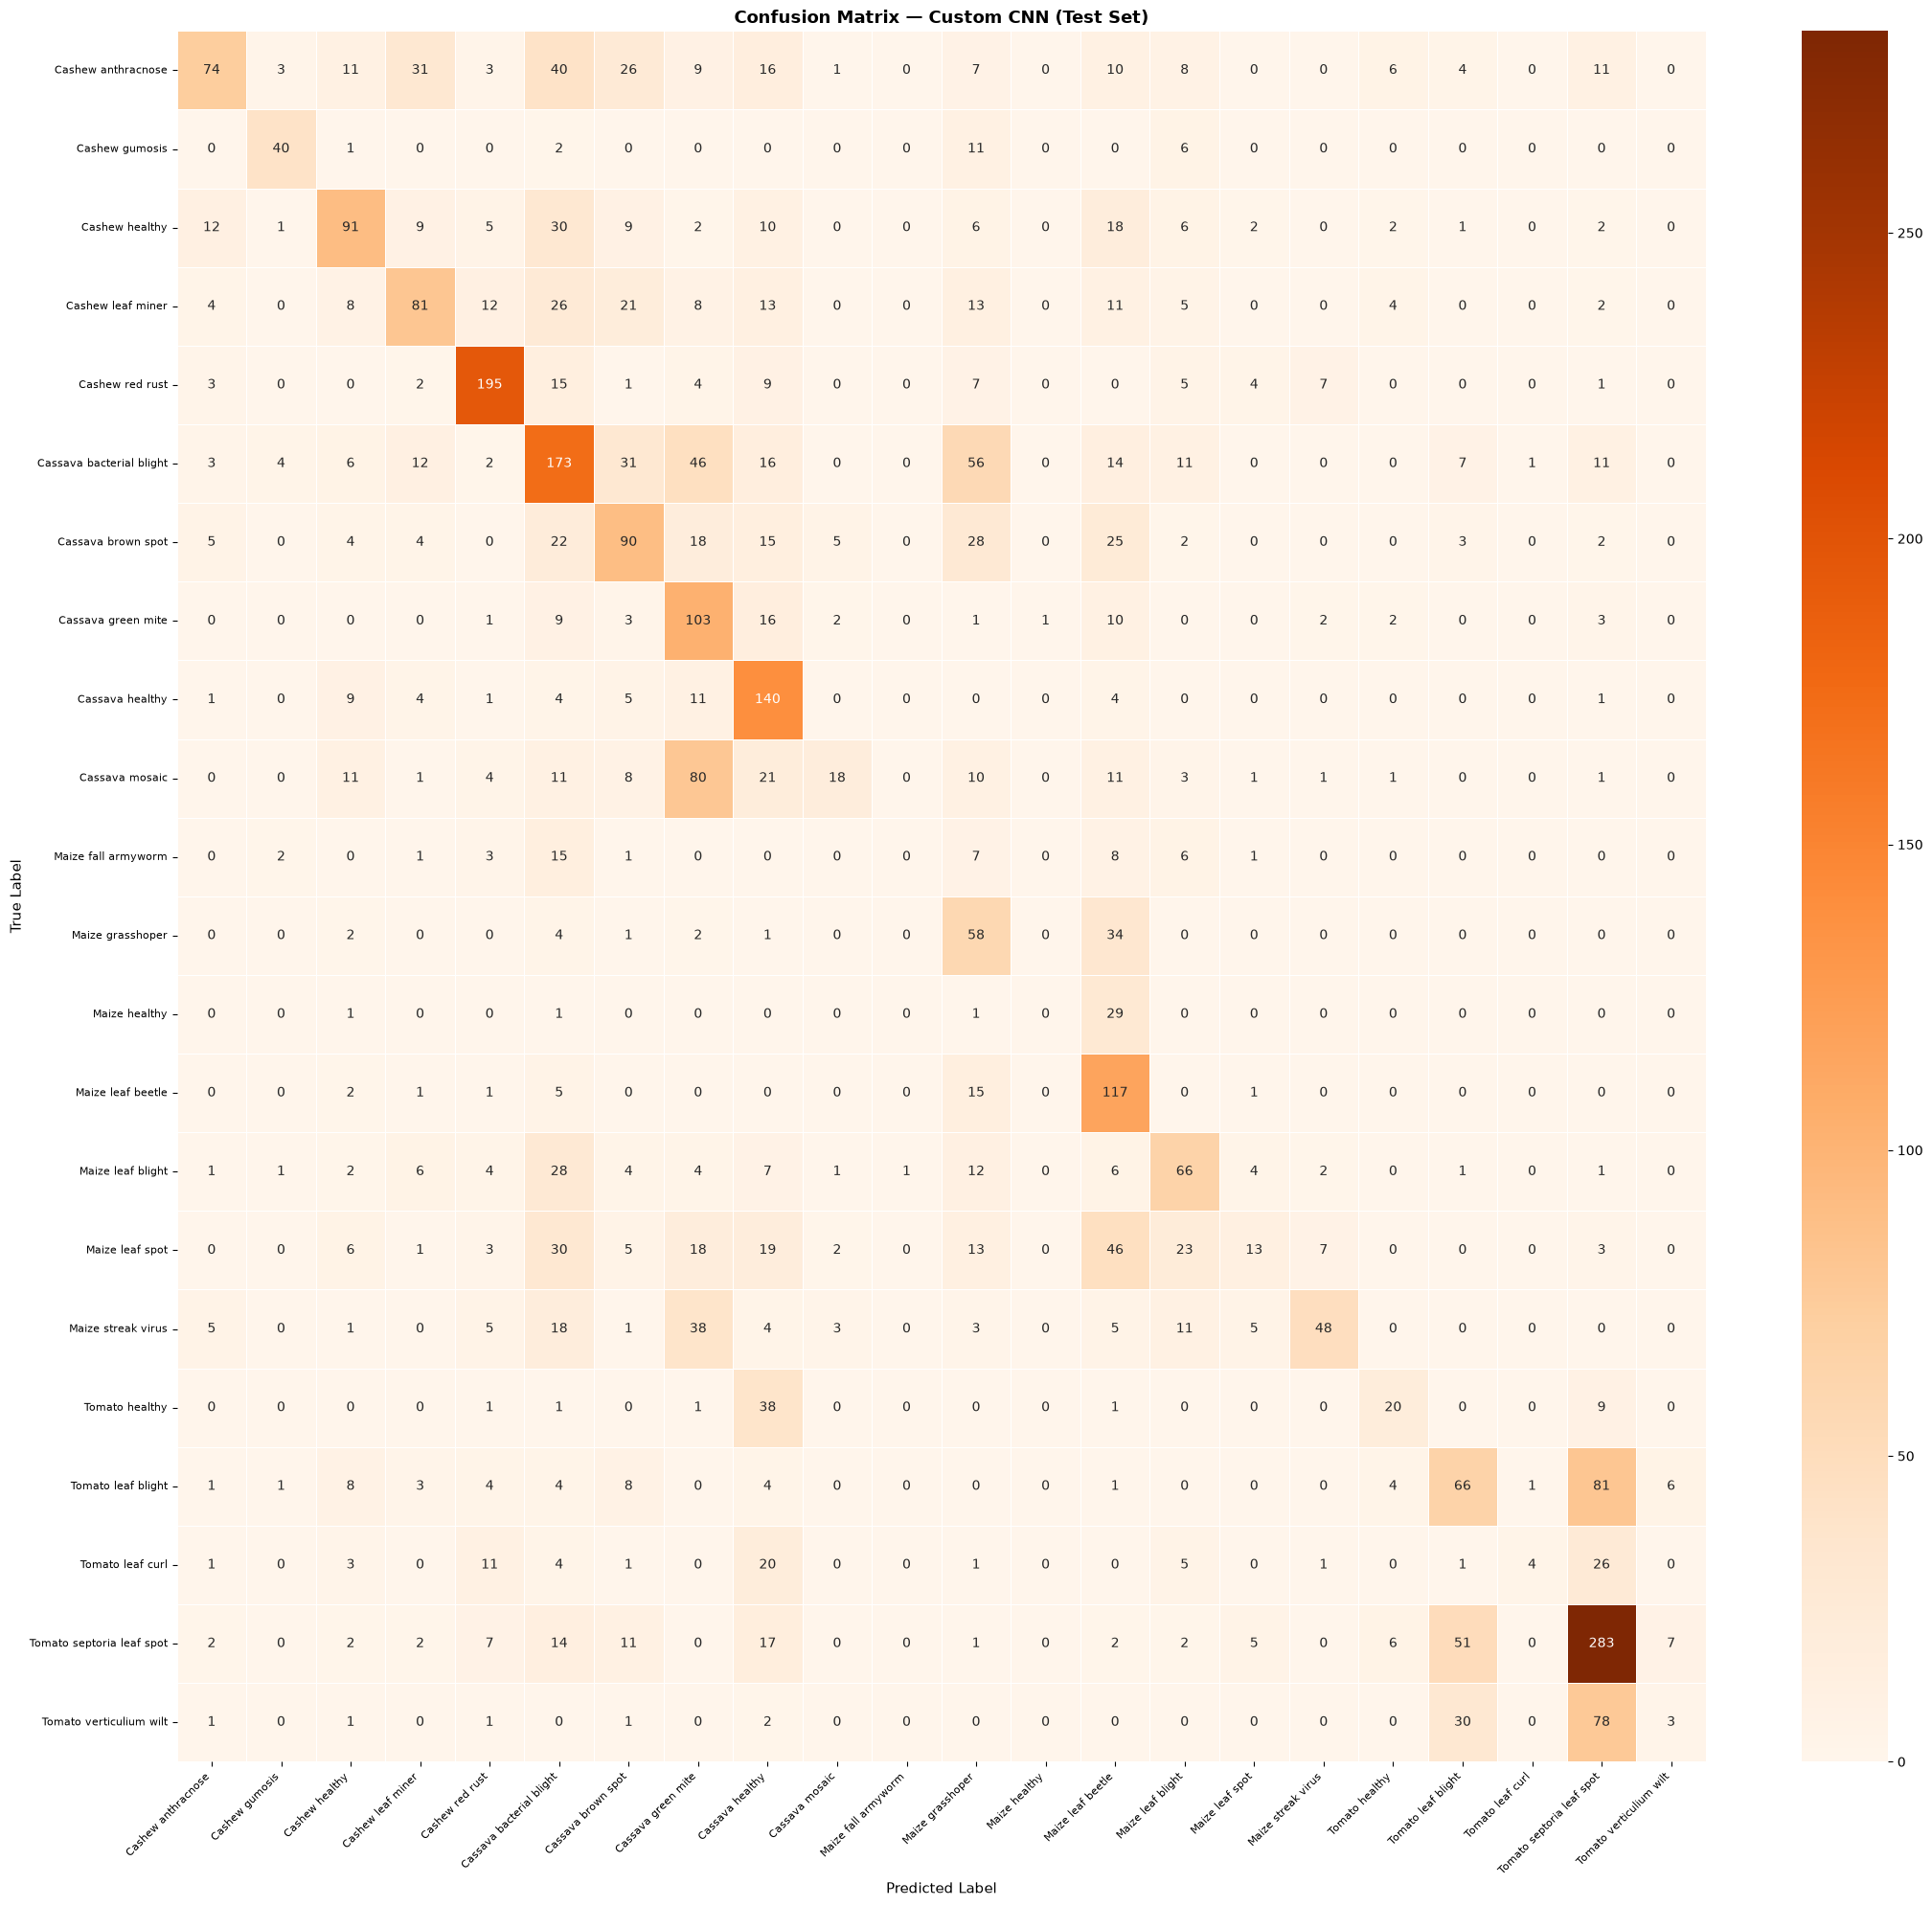

In [17]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(12, NUM_CLASSES), max(10, NUM_CLASSES - 2)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
plt.title("Confusion Matrix — Custom CNN (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11); plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.show()

### CELL 13 ── Per-Class Accuracy Bar Chart


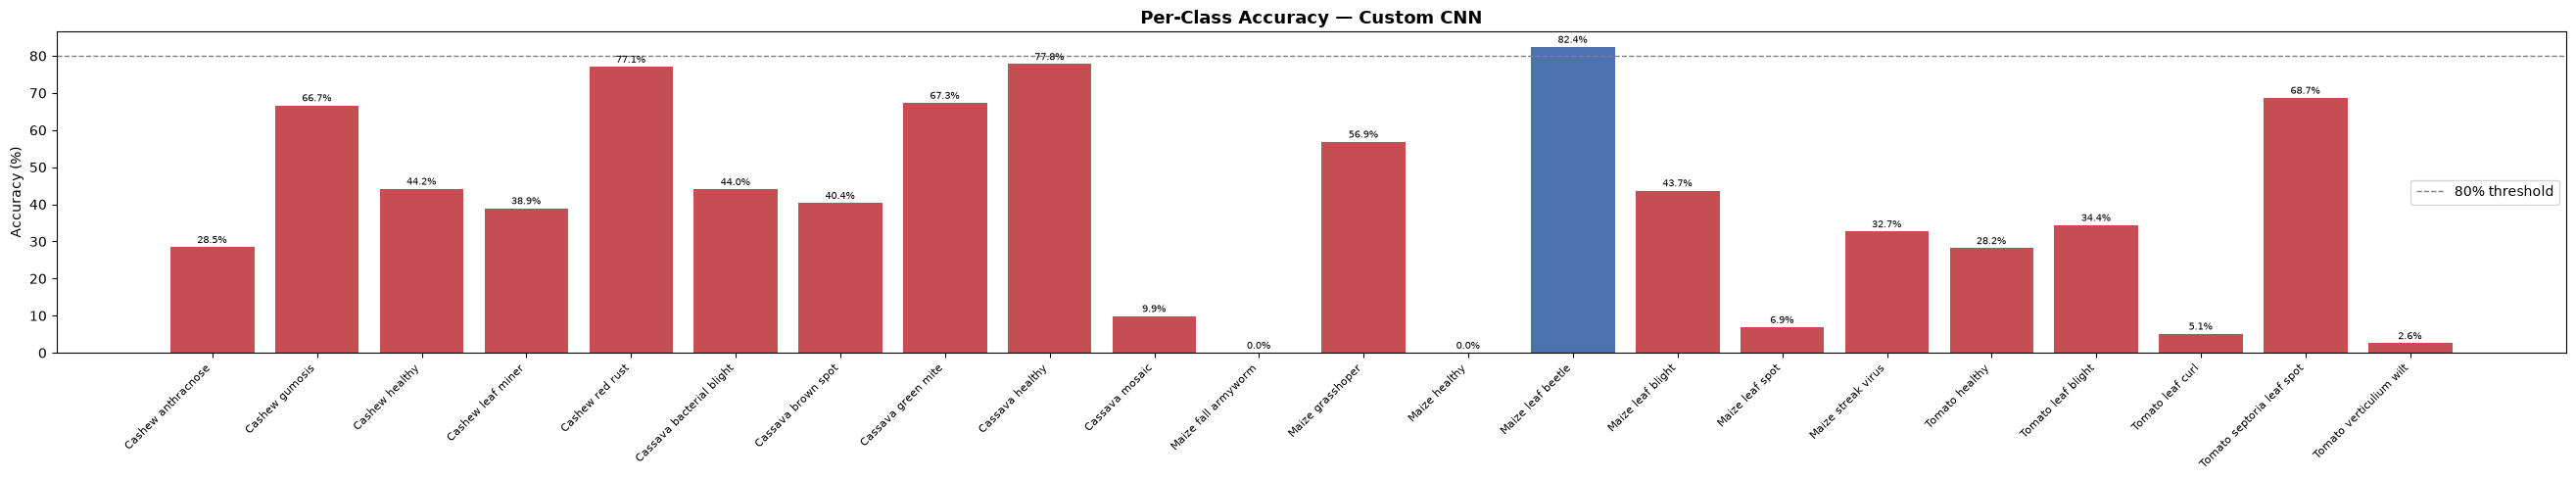

In [18]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(max(12, NUM_CLASSES * 1.2), 5))
colors = ["#4C72B0" if a >= 0.8 else "#C44E52" for a in per_class_acc]
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=colors)
plt.axhline(y=80, color="grey", linestyle="--", linewidth=1, label="80% threshold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.ylabel("Accuracy (%)"); plt.title("Per-Class Accuracy — Custom CNN", fontsize=13, fontweight="bold")
plt.legend()
for bar, acc_val in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{acc_val*100:.1f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

### CELL 14 ── Sample Predictions Grid (Green = Correct, Red = Wrong)


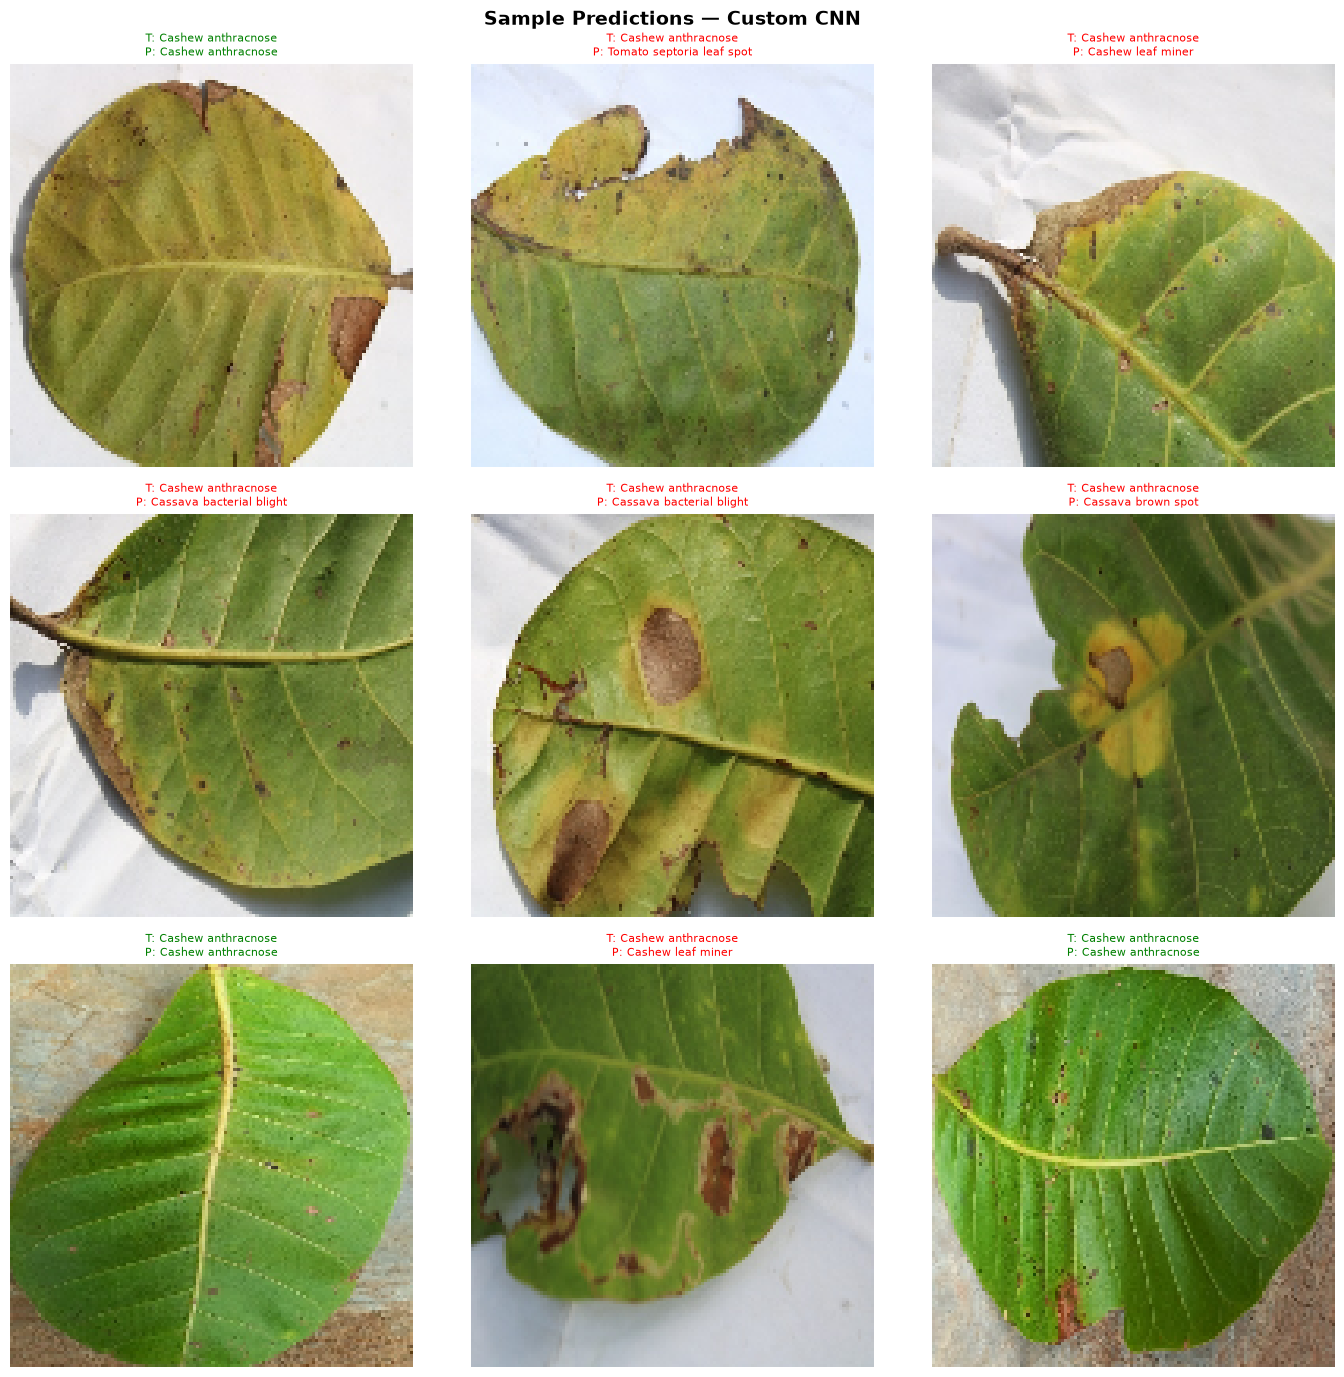

In [19]:
plt.figure(figsize=(14, 14))
plt.suptitle("Sample Predictions — Custom CNN", fontsize=14, fontweight="bold")
for images, labels in test_ds.take(1):
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_lbl = CLASS_NAMES[labels[i]]
        pred_lbl = CLASS_NAMES[preds[i]]
        colour   = "green" if true_lbl == pred_lbl else "red"
        plt.title(f"T: {true_lbl}\nP: {pred_lbl}", color=colour, fontsize=8)
        plt.axis("off")
plt.tight_layout(); plt.show()

### Interpretation of Image-Based Classification Results

In evaluating the sample prediction grid and confusion matrix from a digital image processing perspective:

1. **Visual Cues Leveraged by the Classifier:**
   - **Chromatic Discoloration:** Yellowing chlorotic borders and dark brown/black necrotic patches serve as primary chromatic signals.
   - **Spatial Texture:** Powdery mildew patterns, leaf miner serpentine tracks, and circular fungal spots provide distinct spatial frequency signatures.
2. **Sources of Inter-Class Confusion:**
   - **Morphological Similarity:** Different pathogens can induce visually indistinguishable symptoms (e.g., *Maize leaf blight* vs. *Maize leaf spot* in early developmental stages).
   - **Environmental Artifacts:** Strong sunlight reflections can be misclassified as light-colored fungal sporulation; deep shadows can mimic necrosis.
   - **Background Interference:** Images containing visible soil, human hands, or non-target weeds introduce spurious spatial textures.
3. **Academic Clarification on Evaluation vs. DIP:**
   - A **confusion matrix** is a statistical classification metric, not a digital image processing technique.
   - A **whole-image classification label** indicates the overall diagnosis of the leaf; it does **not** generate pixel-level lesion boundary masks.
   - **Feature activation maps** show which spatial receptive fields triggered filter responses; they do **not** constitute semantic segmentation masks.

### CELL 15 ── Save Final Model


In [21]:
model.save('my_model.keras')
print("Model saved →  CustomCNN_Crop_Disease_Final.keras")

Model saved →  CustomCNN_Crop_Disease_Final.keras


### Digital Image Processing Summary and Case Study Findings

#### 1. Input Image Representation and Dimensions
The Custom CNN operates on standardized $128 \times 128 \times 3$ RGB digital images ($49,152$ total pixel intensity values). Images are loaded from compressed JPEG files and decoded into 8-bit unsigned integer arrays ($[0, 255]$).

#### 2. Image Transformations Applied
- **Geometric Transformations:** Horizontal and vertical spatial reflections, affine rotation ($\pm 90^\circ$), spatial scaling zoom ($\pm 20\%$), and spatial translation ($\pm 10\%$). These enforce rotational and scale invariance against variable camera perspectives.
- **Intensity Transformations:** Contrast stretching ($\pm 15\%$) and additive brightness adjustments ($\pm 10\%$) simulate fluctuating field illumination without altering lesion structures.

#### 3. Pixel Intensity Preprocessing
Raw $[0, 255]$ pixel values undergo data augmentation first, followed by linear normalization to $[0.0, 1.0]$ via `layers.Rescaling(1.0 / 255)`. This ensures gradient stability during backpropagation while keeping intensity transforms on their native scale.

#### 4. Convolutional Feature Extraction
The architecture employs a 5-block hierarchical feature extraction hierarchy utilizing $3 \times 3$ spatial kernels, Batch Normalization, and $2 \times 2$ Max Pooling. Filter capacities scale from $32 \to 64 \to 128 \to 256 \to 512$, followed by Global Average Pooling ($GAP$) to distill 2D spatial feature maps into a 1D feature descriptor.

#### 5. Relevance to Crop Disease Identification
By learning data-driven spatial kernels rather than relying on fixed hand-engineered filters (such as Sobel or Gabor), the network learns to detect subtle necrotic borders, chlorotic margins, and localized pest damage patterns across variable field conditions.

#### 6. Limitations of the Image Processing Approach
- **Lack of Explicit Lesion Segmentation:** Whole-image classification predicts a category for the entire tile but cannot quantify the exact percentage of infected foliar surface area.
- **Spatial Resolution Downsampling:** Resizing to $128 \times 128$ significantly accelerates training but sacrifices high-frequency spatial details required to detect very early micro-symptoms.
- **Sensitivity to Background Interference:** Complex agricultural backgrounds (soil, weeds, shadows) can contaminate feature maps unless suppressed by attentional mechanisms or background subtraction.